# Week 1: Returns and Risk
Pull ten years of daily data for both assets and compute daily returns from the **Adjusted Close** price.

In [2]:
# Load your data from ../data/ (see the setup notebook)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

TICKERS = ["SPY", "RSP"]    # <- change to your pair (exact Yahoo Finance tickers)
SPY_prices = pd.read_csv(f"../data/{TICKERS[0]}.csv", index_col=0, parse_dates=True)
RSP_prices = pd.read_csv(f"../data/{TICKERS[1]}.csv", index_col=0, parse_dates=True)
SPY_prices.tail() #view last 5 rows as an example


daily_ret_SPY = SPY_prices['Adj Close'].pct_change().dropna()
daily_ret_RSP = RSP_prices['Adj Close'].pct_change().dropna()
print(daily_ret_SPY.head()) #view first 5 rows as an example


returns = pd.concat([daily_ret_SPY, daily_ret_RSP], axis=1, join="inner" ).dropna()
returns.columns = ["SPY_ret", "RSP_ret"]

print(returns.head())
print(returns.shape)

Date
2016-01-05    0.001691
2016-01-06   -0.012614
2016-01-07   -0.023991
2016-01-08   -0.010977
2016-01-11    0.000991
Name: Adj Close, dtype: float64
             SPY_ret   RSP_ret
Date                          
2016-01-05  0.001691  0.002375
2016-01-06 -0.012614 -0.018296
2016-01-07 -0.023991 -0.022660
2016-01-08 -0.010977 -0.012211
2016-01-11  0.000991 -0.003194
(2513, 2)


## Visual
A single chart showing **cumulative log-scale returns** for both assets on the same axes.

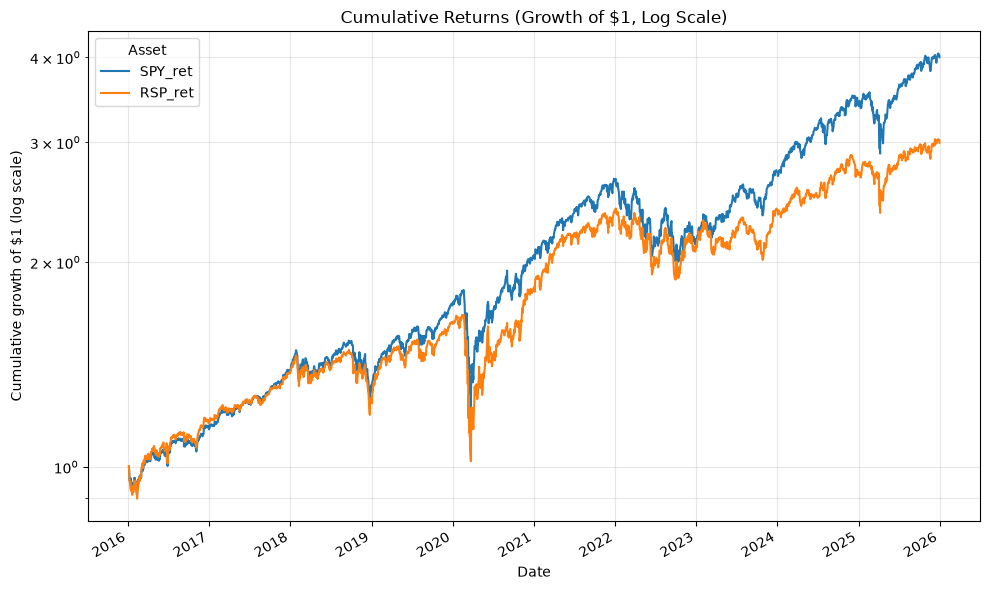

In [3]:
# Growth of $1 invested: cumulative product of (1 + simple return)
growth = (1 + returns).cumprod()

fig, ax = plt.subplots(figsize=(10, 6))
growth.plot(ax=ax, linewidth=1.5)

ax.set_yscale("log")                      # log-scale y-axis
ax.set_title("Cumulative Returns (Growth of $1, Log Scale)")
ax.set_xlabel("Date")
ax.set_ylabel("Cumulative growth of $1 (log scale)")
ax.grid(True, which="both", alpha=0.3)
ax.legend(title="Asset")
plt.tight_layout()
plt.savefig("cumulative_returns.png", dpi=200)
plt.show()

## Table
Side-by-side comparison of **annualized return, annualized volatility, and maximum drawdown**.

In [ ]:
# Annualized return (arithmetic: mean daily return x 252)
ann_ret = returns.mean() * 252 # 252 trading days in a year

# Annualized volatility
ann_vol = returns.std() * np.sqrt(252)

# Maximum drawdown: largest peak-to-trough fall of the growth-of-$1 curve (largest loss from a previous high)
growth = (1 + returns).cumprod() # Makes change in price into a growth-of-$1 curve
running_peak = growth.cummax()  # Tracks the highest value seen so far
drawdown = growth / running_peak - 1  # Calculates the drawdown from the peak
max_dd = drawdown.min()  # Finds the maximum drawdown (largest negative value)

table = pd.DataFrame({
    "Annualized return": ann_ret,
    "Annualized volatility": ann_vol,
    "Maximum drawdown": max_dd,
}).T          # .T puts the metrics in rows and the assets side by side

print((table * 100).round(2).astype(str) + "%") # make everything a percentage and round to 2 decimal places

                       SPY_ret  RSP_ret
Annualized return       15.54%   12.73%
Annualized volatility   18.01%   18.51%
Maximum drawdown       -33.72%  -39.04%


## Context
Find the **five best and five worst days** for each asset, then look up the news to see what caused them.

In [7]:
import pandas as pd

def extremes(returns, n=5):
    """
    Find the n best and n worst daily returns for each asset.

    returns: DataFrame with dates as the index and one column per asset
    n:       how many best/worst days to keep (default 5)

    Returns a dictionary keyed by (asset, "Best"/"Worst"),
    where each value is a Series of returns indexed by date.
    """
    out = {}  # will hold the results, one entry per asset and type

    # Loop over each asset (each column in the DataFrame, e.g. SPY and RSP)
    for col in returns.columns:

        # nlargest(n) sorts the column from highest to lowest
        # and keeps the top n values, i.e. the n best days.
        # The date index stays attached to each value.
        out[(col, "Best")] = returns[col].nlargest(n)

        # nsmallest(n) does the opposite: the n most negative returns,
        # i.e. the n worst days.
        out[(col, "Worst")] = returns[col].nsmallest(n)

    # Return everything so the caller can loop over it or print it
    return out


# Using the function:
# .items() gives ((asset, kind), series) pairs
for (asset, kind), s in extremes(returns).items():
    print(f"\n{asset}: five {kind.lower()} days")

    # Multiply by 100 to show percentages, round to 2 decimals,
    # convert to text, and append a "%" sign for display only
    print((s * 100).round(2).astype(str) + "%")


SPY_ret: five best days
Date
2025-04-09    10.5%
2020-03-24    9.06%
2020-03-13    8.55%
2020-04-06    6.72%
2020-03-26    5.84%
Name: SPY_ret, dtype: str

SPY_ret: five worst days
Date
2020-03-16    -10.94%
2020-03-12     -9.57%
2020-03-09     -7.81%
2025-04-04     -5.85%
2020-06-11     -5.76%
Name: SPY_ret, dtype: str

RSP_ret: five best days
Date
2020-03-24    10.68%
2020-03-13     8.12%
2025-04-09      8.0%
2020-04-06     7.57%
2020-03-26     5.76%
Name: RSP_ret, dtype: str

RSP_ret: five worst days
Date
2020-03-16    -12.04%
2020-03-12    -10.09%
2020-03-09     -8.67%
2020-06-11     -6.92%
2020-03-18     -6.51%
Name: RSP_ret, dtype: str


| Asset | Date | Return | What happened |
|---|---|---|---|
| SPY | 2025-04-09 | +10.5% | Trump announced a 90-day pause on many tariffs, even as he raised the levy on Chinese imports to 125%. The S&P 500 closed 9.5% higher.|
| SPY | 2020-03-224 | +9.06% | Lawmakers said they were close to a deal on an economic rescue package for the coronavirus outbreak, following an unprecedented Federal Reserve move to backstop large parts of the financial system. |
| SPY | 2020-03-13 | +8.55% | Wall Street rebounded from its worst day in 30 years after Trump declared the pandemic a national emergency. |
| SPY | 2020-04-06 | +6.72% | Stocks rallied on hopes that the growth rate of new coronavirus cases may be ebbing. New York reported its first daily decline in virus deaths. |
| SPY | 2020-03-26 | +5.84% | A unanimous Senate vote for a $2 trillion stimulus bill. |
| SPY | 2020-03-16 | -10.94% | he Fed made an emergency cut to near zero and announced a $700 billion asset purchase program. Investors wanted more direct help from the government, and some read the Fed’s move as panic. |
| SPY | 2020-03-12 | -9.57% | Trump’s 30-day ban on most travel from Europe |
| SPY | 2020-03-09 | -7.81% | Saudi Arabia responded to Russia’s refusal to cut output with a full-blown oil price war. Oil had its biggest one-day drop since the Gulf War. A 15-minute trading halt was triggered shortly after the open. |
| SPY | 2025-04-04 | -5.85% | China retaliated against the new US tariffs with its own 34% tariff on all US goods. |
| SPY | 2020-06-11 | -5.76% | The market stalled amid signs of a second COVID wave. The Fed also gave a gloomy outlook the day before. |
| RSP | 2020-03-24  |  +10.68% | stimulus deal hopes |
| RSP | 2020-03-13  |  +8.12% | national emergency declaration | 
| RSP | 2025-04-09  |    +8.0% | tariff pause | 
| RSP | 2020-04-06  |   +7.57% | virus peak hopes |
| RSP | 2020-03-26  |   +5.76% | Senate stimulus bill |
| RSP | 2020-03-16  | -12.04% | Fed cut and pandemic measures |
| RSP | 2020-03-12  |  -10.09% | Europe travel ban |
| RSP | 2020-03-09  |  -8.67% | oil price war |
| RSP | 2020-06-11  |  -6.92% | second-wave fears |
| RSP | 2020-03-18  |   -6.51% | Oil fell 24% to its lowest price since 2002. Chevron fell 22% and Boeing 18%. |

## The Paragraph
> **Which asset is actually riskier, and does taking on that extra risk result in a higher return?**

According to our data it appears that RSP is riskier than SPY as it has a greater annualized volitility of 18.51%, compared to 18.01% for SPY, a half percentange point increase. RSP also has a maxmimum drawdown of -39.04% which is higher than the SPY maxmimum drawdown of -33.72% over the same period. According to these measures RSP appears to be riskier over the 10 year period. This extra risk doesn't appear to materialize in better returns, as the SPY has a greater annualized return of 15.54% compared to the 12.73% annualized return of RSP. Therefore, the extra risk of the RSP doesn't result in a higher return. 

---
**Done?** Restart the kernel and **Run All** to check everything runs top to bottom, then commit
(navigate into your project folder in the terminal first):

```bash
git add .
git commit -m "Week 1: returns and risk"
git push
```